In [1]:
# import torch
# print(torch.__version__)
# print(torch.cuda.is_available())

# Import libs

In [2]:
import matplotlib.pyplot as plt
import scipy.io
import numpy as np

import torch
import torch.optim

from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

from models.skip3D_anisotropic import *
from utils.custom_utils import *

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark = True
dtype = torch.cuda.FloatTensor

# Load image

In [3]:
image = 'dc'
file_name  = f'data/denoising/{image}/denoising.mat'

mat = scipy.io.loadmat(file_name)
img_np = mat["image"][:192, :192, :160]
img_np = img_np.transpose(2, 0, 1)

# Noise levels
snr = 5
laplace = 0
sparse = 0
stripe = 0

sigma = sigma_from_snr(snr, img_np)
print("sigma:", sigma)

img_noisy_np = get_noisy_image(img_np, sigma, laplace=laplace)
img_noisy_np = create_sparse_noise(img_noisy_np, k=sparse)
img_noisy_np, striped_bands = create_stripe_noise(img_noisy_np, k=stripe)
img_noisy_var = torch.from_numpy(img_noisy_np).type(dtype)

sigma_est = sigma_estimate(img_noisy_np)
print("sigma estimate:", sigma_est)

sigma: 0.16775958536690255
sigma estimate: 0.14462986439079867


In [4]:
print("PSNR:", psnr(np.float32(img_np), img_noisy_np))
print("MPSNR:", mpsnr(img_np, img_noisy_np))
print("SSIM:", ssim(img_np, img_noisy_np, data_range=1, channel_axis=0))

PSNR: 16.60227202692206
MPSNR: 15.836587910430495
SSIM: 0.3878105310667031


### Visualize

Noisy image

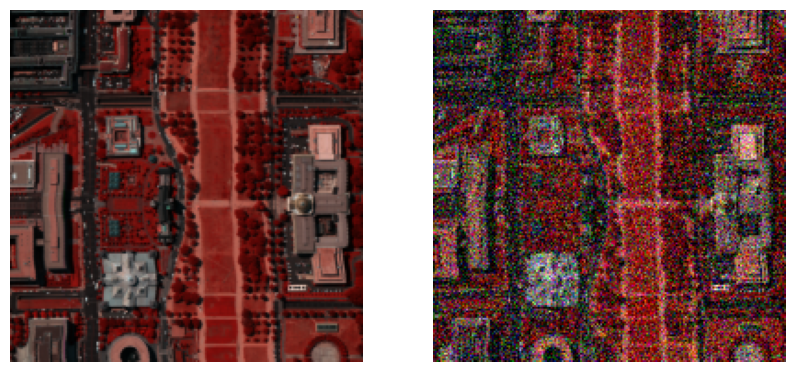

In [5]:
if image == 'dc':
    target_bands = [56, 26, 16]
elif image == 'urban':
    target_bands = [134, 80, 26]

if stripe > 0:
    bands = striped_bands[np.abs(striped_bands[:, None] - target_bands).argmin(axis=0)]
else:
    bands = target_bands

f, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(10, 10))
ax1.imshow(np.stack((img_np[bands[0],:,:], img_np[bands[1],:,:], img_np[bands[2],:,:]), 0).transpose(1, 2, 0))
ax2.imshow(np.stack((img_noisy_np[bands[0],:,:], img_noisy_np[bands[1],:,:], img_noisy_np[bands[2],:,:]), 0).transpose(1, 2, 0))
ax1.axis('off')
ax2.axis('off')
plt.show()

# Setup

In [ ]:
sure = True
eps = 1e-3
norm = 1

method = '3D'
OPT_OVER = 'net,input' # 'net'

reg_noise_std = 0
LR = 0.01

OPTIMIZER = 'adam' # 'LBFGS'
exp_weight = 0.99
sstv_weight = 0
tv_weight = 0

show_every = 200
save_every = 200

num_iter = 201
input_depth = img_np.shape[0]  

# 2D conv
# net = skip(input_depth, img_np.shape[0],
#         num_channels_down=[128]*5, num_channels_up=[128]*5, num_channels_skip=[4]*5,
#         filter_size_up=3, filter_size_down=3, filter_skip_size=1,
#         upsample_mode='bilinear', # downsample_mode='avg',
#         need1x1_up=False, need_sigmoid=True, need_bias=True, pad='reflection', act_fun='LeakyReLU').type(dtype)

# (2+1)D separable conv (full model)
# net = skip3(1, 1, 
#         num_channels_down=[128]*5, num_channels_up=[128]*5, num_channels_skip=[4]*5,
#         filter_size_up=3, filter_size_down=3, filter_skip_size=1,
#         upsample_mode='nearest', # downsample_mode='avg',
#         need1x1_up=False, need_sigmoid=False, need_bias=True, pad='reflection', act_fun='LeakyReLU').type(dtype)

# (2+1)D separable model (reduced model)
net = skip3(1, 1, 
        num_channels_down=[8, 16, 32, 64, 128], num_channels_up=[8, 16, 32, 64, 128], num_channels_skip=[0, 0, 0, 4, 4], 
        upsample_mode='nearest',
        need1x1_up=False, need_sigmoid=False, need_bias=True,
        pad='reflection', act_fun='LeakyReLU').type(dtype)

# 3D conv (full model)
# net = skip(1, 1, 
#         num_channels_down=[128]*5, num_channels_up=[128]*5, num_channels_skip=[4]*5,
#         filter_size_up=3, filter_size_down=3, filter_skip_size=1,
#         upsample_mode='trilinear', # downsample_mode='avg',
#         need1x1_up=False, need_sigmoid=False, need_bias=True, pad='reflection', act_fun='LeakyReLU').type(dtype)

# 3D conv (reduced model)
# net = skip(1, 1, 
#         num_channels_down=[8, 16, 32, 64, 128], num_channels_up=[8, 16, 32, 64, 128], num_channels_skip=[0, 0, 0, 4, 4], 
#         upsample_mode='trilinear',
#         need1x1_up=False, need_sigmoid=False, need_bias=True,
#         pad='reflection', act_fun='LeakyReLU').type(dtype)

img_noisy_var = img_noisy_var[None, None, :].cuda()

if sure:
    net_input = img_noisy_var.detach().clone()
else:
    net_input = get_noise(input_depth, method, (img_np.shape[1], img_np.shape[2])).type(dtype).detach()
    if norm == 2:
        loss = torch.nn.MSELoss().type(dtype)
    elif norm == 1:
        loss = torch.nn.SmoothL1Loss(beta=0.001).type(dtype)

# Compute number of parameters
s = sum([np.prod(list(p.size())) for p in net.parameters()]) 
print ('Number of params: %d' % s)

Number of params: 494165


c:\Users\pagko\miniconda3\envs\hsi\Lib\site-packages\torch\nn\init.py:511: UserWarning: Initializing zero-element tensors is a no-op
  warnings.warn("Initializing zero-element tensors is a no-op")


# Optimize

In [ ]:
net_input_saved = net_input.detach().clone()
noise = net_input.detach().clone()
out_avg = None
last_net = None
psnr_noisy_last = 0

mpsnr_list = []
ssim_list = []
nmse_list = []
loss_list = []

i = 0
def closure():
    
    global i, out_avg, psnr_noisy_last, last_net, net_input
    
    if reg_noise_std > 0:
        net_input = net_input_saved + (noise.normal_() * reg_noise_std)
    
    out = net(net_input)
    
    # Smoothing
    if out_avg is None:
        out_avg = out.detach()
    else:
        out_avg = out_avg * exp_weight + out.detach() * (1 - exp_weight)

    # Loss
    if sure:
        total_loss = sure_loss(out, img_noisy_var, sigma_est, net, epsilon=eps, norm=norm)
    elif norm == 0.5:        
        total_loss = l_half_norm(out, img_noisy_var)
    else:
        total_loss = loss(out, img_noisy_var)
    
    if sstv_weight > 0:
        total_loss += sstv_weight * sstv_loss(out)
    
    if tv_weight > 0:
        total_loss += tv_weight * tv_loss(out)
    
    total_loss.backward()
    
    net_input_np = net_input.detach().cpu().squeeze().numpy()
    out_np = out.detach().cpu().squeeze().numpy()
    out_avg_np = out_avg.detach().cpu().squeeze().numpy()

    psnr_noisy  = mpsnr(img_noisy_np.astype(np.float32), np.clip(out_np, 0, 1))
    psnr_gt     = mpsnr(img_np.astype(np.float32), np.clip(out_np, 0, 1))
    psnr_gt_avg = mpsnr(img_np.astype(np.float32), np.clip(out_avg_np, 0, 1))

    mpsnr_list.append(psnr_gt_avg)
    nmse_list.append(nmse(img_np.astype(np.float32), np.clip(out_avg_np, 0, 1)))
    loss_list.append(total_loss.item())

    print ('Iteration: %04d Loss: %f MPSNR_gt: %f MPSNR_gt_avg: %f' % (i, total_loss.item(), psnr_gt, psnr_gt_avg), '\r', end='')
    
    if i % show_every == 0:
        net_input_np = np.clip(net_input_np, 0, 1)
        out_np = np.clip(out_np, 0, 1)
        out_avg_np = np.clip(out_avg_np, 0, 1)

        mssim_gt     = ssim(img_np.astype(np.float32), out_np, data_range = 1, channel_axis = 0)
        mssim_gt_avg = ssim(img_np.astype(np.float32), out_avg_np, data_range = 1, channel_axis = 0)
        print('\n' + 'SSIM_gt: %f SSIM_gt_avg: %f' % (mssim_gt, mssim_gt_avg))
        ssim_list.append(mssim_gt_avg)
        # psnr_1 = psnr(img_np.astype(np.float32), np.clip(out_np, 0, 1))
        # psnr_2 = psnr(img_np.astype(np.float32), np.clip(out_avg_np, 0, 1))
        # print('PSNR_gt: %f PSNR_gt_avg: %f' % (psnr_1, psnr_2))
        
        f, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(10, 10))
        ax1.imshow(np.stack((out_np[bands[0],:,:], out_np[bands[1],:,:], out_np[bands[2],:,:]), 2))
        ax2.imshow(np.stack((out_avg_np[bands[0],:,:], out_avg_np[bands[1],:,:], out_avg_np[bands[2],:,:]), 2))
        ax1.axis('off')
        ax2.axis('off')
        plt.show()

    # if  i % save_every == 0:
        # scipy.io.savemat(f"results/{image}/mat_files/result_denoising_2D_it%05d.mat" % (i), {'pred':out_np.transpose(1, 2, 0), 'pred_avg':out_avg_np.transpose(1, 2, 0)})
        
    # Backtracking
    if i % show_every:
        if psnr_noisy - psnr_noisy_last < -5: 
            print('Falling back to previous checkpoint.')

            for new_param, net_param in zip(last_net, net.parameters()):
                net_param.detach().copy_(new_param.cuda())

            return total_loss*0
        else:
            last_net = [x.detach().cpu() for x in net.parameters()]
            psnr_noisy_last = psnr_noisy
            
    i += 1

    return total_loss

p = get_params(OPT_OVER, net, net_input)
optimize(OPTIMIZER, p, closure, LR, num_iter)

Starting optimization with ADAM


OutOfMemoryError: CUDA out of memory. Tried to allocate 1.41 GiB. GPU 0 has a total capacity of 8.00 GiB of which 0 bytes is free. Of the allocated memory 13.73 GiB is allocated by PyTorch, and 7.55 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

Plots of training curves

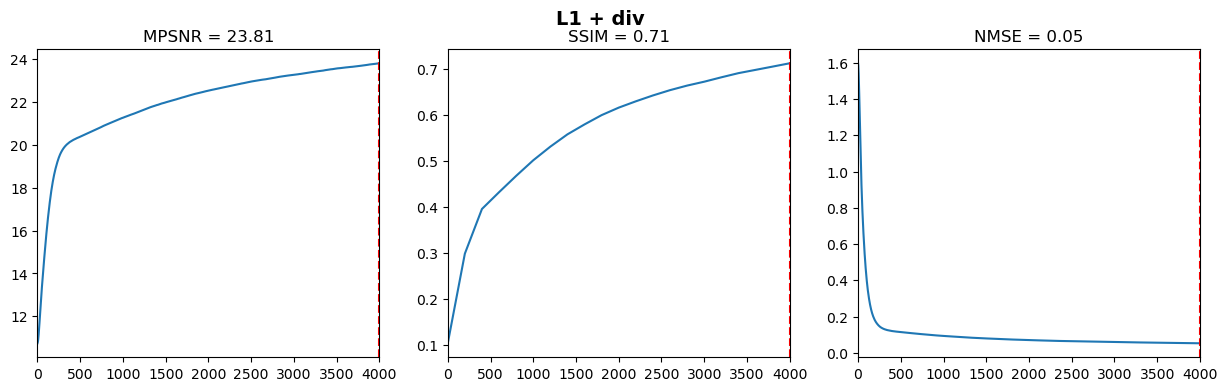

In [12]:
no = 42
if sure:
    if norm == 2:
        title = 'SURE'
    elif norm == 1:
        title = 'L1 + div'
    elif norm == 0.5:
        title = r'$L_{0.5}$ + div'
else:
    if norm == 2:
        title = 'L2'
    elif norm == 1:
        title = 'L1'
    elif norm == 0.5:
        title = r'$L_{0.5}$'

np.savez(f'results/{image}/npz_files/{no}.npz', mpsnr=mpsnr_list, ssim=ssim_list, nmse=nmse_list, loss=loss_list)

f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

ax1.plot(np.arange(0, num_iter), mpsnr_list)
ax1.set_title(f'MPSNR = {max(mpsnr_list):.2f}')
ax1.axvline(np.argmax(mpsnr_list), color='r', ls='--')
ax1.set_xlim(0, num_iter - 1)

ax2.plot(np.arange(0, num_iter, show_every), ssim_list)
ax2.axvline(np.argmax(ssim_list)*show_every, color='r', ls='--')
ax2.set_title(f'SSIM = {max(ssim_list):.2f}')
ax2.set_xlim(0, num_iter - 1)

ax3.plot(np.arange(0, num_iter), nmse_list)
ax3.axvline(np.argmin(nmse_list), color='r', ls='--')
ax3.set_title(f'NMSE = {min(nmse_list):.2f}')
ax3.set_xlim(0, num_iter - 1)

plt.suptitle(title, weight='bold', fontsize=14)
plt.savefig(f'results/{image}/plots/{no}.png')
plt.show()

Comparisons of different trainings

In [ ]:
# image = 'dc'
# num_iter = 4001
# show_every = 200

# list_mpsnr = []
# list_ssim = []
# list_nmse = []
# list_title = ['L1 + div', 'L1 + div (net + input optimization)']
# nums = '424'

# for i in [4, 24]:
#     results = np.load(f'results/{image}/npz_files/{i}.npz')
#     list_mpsnr.append(list(results['mpsnr']))
#     list_ssim.append(list(results['ssim']))
#     list_nmse.append(list(results['nmse']))

# f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# for data, title in zip(list_mpsnr, list_title):
#     ax1.plot(np.arange(0, num_iter), data, label=title)
# ax1.legend(loc='lower right')
# ax1.set_xlim(0, num_iter - 1)
# ax1.set_xlabel('Iterations')
# ax1.set_ylabel('MPSNR')
# ax1.set_title('MPSNR')

# for data, title in zip(list_ssim, list_title):
#     ax2.plot(np.arange(0, num_iter, show_every), data, label=title)
# ax2.legend(loc='lower right')
# ax2.set_xlim(0, num_iter - 1)
# ax2.set_xlabel('Iterations')
# ax2.set_ylabel('SSIM')
# ax2.set_title('SSIM')

# for data, title in zip(list_nmse, list_title):
#     ax3.plot(np.arange(0, num_iter), data, label=title)
# ax3.legend(loc='upper right')
# ax3.set_xlim(0, num_iter - 1)
# ax3.set_yscale('log')
# ax3.set_xlabel('Iterations')
# ax3.set_ylabel('NMSE')
# ax3.set_title('NMSE')

# plt.suptitle('Gaussian 10 dB + sparse 5%', weight='bold', fontsize=14)
# plt.savefig(f'results/{image}/plots/comp_{nums}.png')
# plt.show()